# 03. Frontier models reference on the SemEval PL pilot: gpt-6-luna and Claude Opus 5.5

Two reference runs with models from OpenAI and Anthropic on the same 219 pilot paragraphs as the first Bielik run
(SemEval-2023 Task 3 subtask 3, Polish, official train split, role `pilot`, 11 articles).

**gpt-6-luna, OpenAI Decisions API**

- Run: `python -m routing.decisions_api` (one request per paragraph, 23 predicate questions, P1 instructions and definitions)
- The API returns a probability per technique; a technique is predicted when p >= 0.5
- The API has no temperature or seed, so every request was sent 5 times to check self-consistency

**Claude Opus 5.5 through the Claude Code CLI**
- Run: `python -m routing.claude_cli` (one `claude -p` call per paragraph and repeat, effort `low`)
- Prompt P1 as the user message, exactly as for Bielik; no tools, no settings, empty working directory
- The JSON schema of the answer is the same as for Bielik (23 keys, 0/1)
- Differences from the Bielik setting: a one-sentence neutral system prompt replaces the Claude Code one
  (Bielik has none), no temperature control (the model's default sampling), no token probabilities
- 5 independent calls per paragraph, majority vote as for Bielik

- Bielik numbers come from `outputs/public/bielik_semeval_pl_pilot_p1/items.csv`

In [1]:
import json

import numpy as np
import pandas as pd

from routing.data import REPO_ROOT, load_role
from routing.labels import labels_for
from routing.metrics import auroc, cluster_bootstrap_ci, task_quality
from routing.signals import majority_vote, mean_pairwise_jaccard, modal_set_frequency

LABELS = list(labels_for("semeval_pl"))
RUN = REPO_ROOT / "outputs" / "runs" / "gpt6luna_semeval_pl_pilot_decisions" / "generations.jsonl"

items = load_role("semeval_pl", "pilot").reset_index(drop=True)
gold = items[LABELS].to_numpy()
row = {item_id: k for k, item_id in enumerate(items["item_id"])}

records = [json.loads(line) for line in RUN.read_text().splitlines()]
n_repeats = max(r["repeat"] for r in records) + 1
probs = np.full((len(items), n_repeats, len(LABELS)), np.nan)  # item x repeat x technique
for r in records:
    probs[row[r["item_id"]], r["repeat"]] = r["p1"]

OPUS_RUN = REPO_ROOT / "outputs" / "runs" / "opus55cli_semeval_pl_pilot_p1" / "generations.jsonl"
opus_records = [json.loads(line) for line in OPUS_RUN.read_text().splitlines()]
opus_runs = np.full((len(items), 5, len(LABELS)), -1)  # item x repeat x technique
for r in opus_records:
    opus_runs[row[r["item_id"]], r["repeat"]] = r["labels"]
opus_vote = np.array([majority_vote(runs) for runs in opus_runs])
print(f"Opus: {len(opus_records)} calls, {sum(r['error'] is not None for r in opus_records)} errors, "
      f"models: {sorted({m for r in opus_records for m in r['models']})}, missing runs: {int((opus_runs < 0).any(axis=2).sum())}")
print(f"{len(items)} paragraphs, {n_repeats} repeats, {len(records)} requests, "
      f"{sum(r['error'] is not None for r in records)} errors, {int(np.isnan(probs).sum())} missing probabilities")

Opus: 1095 calls, 0 errors, models: ['claude-opus-5-5'], missing runs: 0
219 paragraphs, 5 repeats, 1095 requests, 0 errors, 0 missing probabilities


## 1. Are the repeats different at all?

gpt-6-luna:

In [2]:
max_change = np.abs(probs - probs[:, :1]).max(axis=(1, 2))
decisions = (probs >= 0.5).astype(int)
same_decisions = (decisions == decisions[:, :1]).all(axis=(1, 2))
print(f"paragraphs where any probability changed between repeats: {(max_change > 0).mean():.1%}")
print(f"paragraphs with identical decisions in all repeats:       {same_decisions.mean():.1%}")

paragraphs where any probability changed between repeats: 0.0%
paragraphs with identical decisions in all repeats:       100.0%


The API is deterministic: all repeats return exactly the same probabilities. Self-consistency
(agreement between repeats) is therefore 1 for every paragraph and carries no information. From here on
repeat 0 is used and the only confidence comes from the returned probabilities.

Claude Opus 5.5:

In [3]:
opus_same = (opus_runs == opus_runs[:, :1]).all(axis=(1, 2))
print(f"paragraphs with identical decisions in all 5 calls: {opus_same.mean():.1%}")
print("exact-set accuracy of single calls:", [round(float((opus_runs[:, k] == gold).all(axis=1).mean()), 3) for k in range(5)])

paragraphs with identical decisions in all 5 calls: 56.6%
exact-set accuracy of single calls: [0.26, 0.274, 0.297, 0.288, 0.279]


## 2. Task quality compared with Bielik and a trivial baseline

In [4]:
p = probs[:, 0]
predicted = (p >= 0.5).astype(int)

bielik = pd.read_csv(REPO_ROOT / "outputs" / "public" / "bielik_semeval_pl_pilot_p1" / "items.csv",
                     dtype={"vote_bits": str, "gold_bits": str})
bielik =bielik.set_index("item_id").loc[items["item_id"]].reset_index()
bielik_vote = np.array([[int(c) for c in bits] for bits in bielik["vote_bits"]])
assert (np.array([[int(c) for c in bits] for bits in bielik["gold_bits"]]) == gold).all()

systems = {
    "gpt-6-luna (Decisions API)": predicted,
    "Claude Opus 5.5 (vote of 5)": opus_vote,
    "Bielik-11B (vote of 5)": bielik_vote,
    "always no technique": np.zeros_like(gold),
}
articles = items["article_id"].to_numpy()
rows = []
for name, pred in systems.items():
    quality = task_quality(gold, pred)
    correct = (pred == gold).all(axis=1)
    low, high = cluster_bootstrap_ci(lambda idx: correct[idx].mean(), articles)
    rows.append({"system": name, "exact-set acc": quality["exact_set_accuracy"], "95% CI (articles)": f"{low:.2f}-{high:.2f}",
                 "micro-F1": quality["micro_f1"], "micro-P": quality["micro_precision"], "micro-R": quality["micro_recall"],
                 "macro-F1": quality["macro_f1"], "mean labels predicted": pred.sum(axis=1).mean()})
pd.DataFrame(rows).round(3)

,system,exact-set acc,95% CI (articles),micro-F1,micro-P,micro-R,macro-F1,mean labels predicted
0,gpt-6-luna (Decisions API),0.210,0.09-0.36,0.283,0.188,0.573,0.253,2.676
1,Claude Opus 5.5 (vote of 5),0.288,0.14-0.46,0.383,0.288,0.573,0.286,1.744
2,Bielik-11B (vote of 5),0.311,0.20-0.45,0.285,0.228,0.380,0.200,1.461
3,always no technique,0.457,0.31-0.61,0.000,0.000,0.000,0.000,0.000


In [5]:
print(f"gold labels per paragraph: mean {gold.sum(axis=1).mean():.2f}, empty in {(gold.sum(axis=1) == 0).mean():.1%}")
gold_empty = gold.sum(axis=1) == 0
for name, pred in list(systems.items())[:3]:
    pred_empty = pred.sum(axis=1) == 0
    print(f"{name:28s} predicts empty in {pred_empty.mean():.1%}; "
          f"right on empty gold {((pred == gold).all(axis=1) & gold_empty).sum()}/{gold_empty.sum()}, "
          f"on non-empty gold {((pred == gold).all(axis=1) & ~gold_empty).sum()}/{(~gold_empty).sum()}")

gold labels per paragraph: mean 0.88, empty in 45.7%
gpt-6-luna (Decisions API)   predicts empty in 22.8%; right on empty gold 44/100, on non-empty gold 2/119
Claude Opus 5.5 (vote of 5)  predicts empty in 29.2%; right on empty gold 56/100, on non-empty gold 7/119
Bielik-11B (vote of 5)       predicts empty in 38.4%; right on empty gold 60/100, on non-empty gold 8/119


Per technique (only techniques present in the gold labels of the pilot):

In [6]:
from sklearn.metrics import f1_score

per_label = pd.DataFrame({
    "gold": gold.sum(axis=0),
    "gpt predicted": predicted.sum(axis=0),
    "gpt F1": f1_score(gold, predicted, average=None, zero_division=0),
    "Opus predicted": opus_vote.sum(axis=0),
    "Opus F1": f1_score(gold, opus_vote, average=None, zero_division=0),
    "Bielik predicted": bielik_vote.sum(axis=0),
    "Bielik F1": f1_score(gold, bielik_vote, average=None, zero_division=0),
}, index=LABELS)
per_label[per_label["gold"] > 0].sort_values("gold", ascending=False).round(2)

,gold,gpt predicted,gpt F1,Opus predicted,Opus F1,Bielik predicted,Bielik F1
Name_Calling-Labeling,42,37,0.56,41,0.75,26,0.53
Doubt,28,62,0.42,47,0.37,49,0.36
Loaded_Language,18,118,0.25,80,0.33,56,0.38
Appeal_to_Hypocrisy,15,9,0.33,10,0.32,11,0.38
Appeal_to_Authority,14,31,0.49,33,0.47,13,0.37
Questioning_the_Reputation,13,27,0.35,36,0.37,26,0.31
Appeal_to_Fear-Prejudice,9,38,0.26,14,0.61,16,0.16
Conversation_Killer,9,9,0.22,5,0.43,1,0.20
Flag_Waving,7,4,0.55,4,0.36,2,0.22
Appeal_to_Values,6,26,0.38,9,0.40,10,0.25


gpt-6-luna only: does a different threshold help? (Chosen on the same data, so only to see how sensitive the result is,
not a result to report.)

In [7]:
rows = []
for threshold in (0.3, 0.5, 0.7, 0.8, 0.9):
    quality = task_quality(gold, (p >= threshold).astype(int))
    rows.append({"threshold": threshold, **{k: quality[k] for k in ("exact_set_accuracy", "micro_f1", "micro_precision", "micro_recall")}})
pd.DataFrame(rows).round(3)

,threshold,exact_set_accuracy,micro_f1,micro_precision,micro_recall
0,0.3,0.196,0.274,0.175,0.630
1,0.5,0.210,0.283,0.188,0.573
2,0.7,0.247,0.297,0.209,0.510
3,0.8,0.306,0.309,0.240,0.432
4,0.9,0.411,0.329,0.335,0.323


## 3. Confidence signals: does the score predict an exactly right set?

Signals for gpt-6-luna, all from repeat 0:
- **set probability**: product over techniques of max(p, 1 - p), the probability of the predicted set if techniques were independent
- **smallest margin**: min over techniques of |p - 0.5|
- **fewer predicted labels**: minus the number of predicted techniques (the trivial control that was best for Bielik)
- **self-consistency**: constant 1, AUROC undefined (0.5)

Signals for Claude Opus 5.5, from its 5 calls:
- **self-consistency**: mean pairwise Jaccard and modal-set frequency, as for Bielik
- **fewer predicted labels** of the vote

The Bielik rows are the same signals from its run, on the same paragraphs.

In [8]:
gpt_correct = (predicted == gold).all(axis=1)
gpt_signals = {
    "set probability": np.prod(np.maximum(p, 1 - p), axis=1),
    "smallest margin": np.abs(p - 0.5).min(axis=1),
    "fewer predicted labels": -predicted.sum(axis=1).astype(float),
}
rows = []
for name, score in gpt_signals.items():
    low, high = cluster_bootstrap_ci(lambda idx: auroc(gpt_correct[idx], score[idx]), articles)
    rows.append({"model": "gpt-6-luna", "signal": name, "AUROC": auroc(gpt_correct, score), "95% CI (articles)": f"{low:.2f}-{high:.2f}"})
rows.append({"model": "gpt-6-luna", "signal": "self-consistency (5 repeats)", "AUROC": np.nan, "95% CI (articles)": "constant"})

opus_correct = (opus_vote == gold).all(axis=1)
opus_signals = {
    "consistency: mean pairwise Jaccard": np.array([mean_pairwise_jaccard(runs) for runs in opus_runs]),
    "consistency: modal-set frequency": np.array([modal_set_frequency(runs) for runs in opus_runs]),
    "fewer predicted labels": -opus_vote.sum(axis=1).astype(float),
}
for name, score in opus_signals.items():
    low, high = cluster_bootstrap_ci(lambda idx: auroc(opus_correct[idx], score[idx]), articles)
    rows.append({"model": "Claude Opus 5.5", "signal": name, "AUROC": auroc(opus_correct, score), "95% CI (articles)": f"{low:.2f}-{high:.2f}"})

bielik_correct = bielik["correct"].to_numpy()
for column in ("consistency: mean pairwise Jaccard", "log-probability: voted set, teacher-forced",
               "verbalised confidence", "control: fewer predicted labels"):
    score = bielik[column].to_numpy(dtype=float)
    low, high = cluster_bootstrap_ci(lambda idx: auroc(bielik_correct[idx], score[idx]), articles)
    rows.append({"model": "Bielik-11B", "signal": column, "AUROC": auroc(bielik_correct, score), "95% CI (articles)": f"{low:.2f}-{high:.2f}"})
pd.DataFrame(rows).round(3)

,model,signal,AUROC,95% CI (articles)
0,gpt-6-luna,set probability,0.928,0.86-0.97
1,gpt-6-luna,smallest margin,0.901,0.82-0.94
2,gpt-6-luna,fewer predicted labels,0.976,0.96-0.99
3,gpt-6-luna,self-consistency (5 repeats),NaN,constant
4,Claude Opus 5.5,consistency: mean pairwise Jaccard,0.607,0.54-0.69
5,Claude Opus 5.5,consistency: modal-set frequency,0.659,0.60-0.72
6,Claude Opus 5.5,fewer predicted labels,0.957,0.93-0.98
7,Bielik-11B,consistency: mean pairwise Jaccard,0.569,0.43-0.68
8,Bielik-11B,"log-probability: voted set, teacher-forced",0.722,0.61-0.83
9,Bielik-11B,verbalised confidence,0.685,0.64-0.73


Accuracy at a given share of paragraphs left to the model (risk-coverage), ranked by each signal:

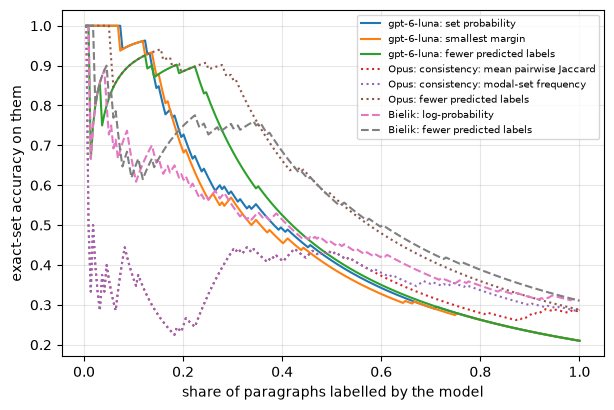

In [9]:
import matplotlib.pyplot as plt

def coverage_curve(correct: np.ndarray, score: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    # stable sort on the negated score, ties keep the item order
    order = np.argsort(-score, kind="stable")
    hits = np.cumsum(correct[order])
    n = np.arange(1, len(order) + 1)
    return n / len(order), hits / n

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, score in gpt_signals.items():
    ax.plot(*coverage_curve(gpt_correct, score), label=f"gpt-6-luna: {name}")
for name, score in opus_signals.items():
    ax.plot(*coverage_curve(opus_correct, score), ":", label=f"Opus: {name}")
ax.plot(*coverage_curve(bielik_correct, bielik["log-probability: voted set, teacher-forced"].to_numpy()), "--",
        label="Bielik: log-probability")
ax.plot(*coverage_curve(bielik_correct, bielik["control: fewer predicted labels"].to_numpy()), "--",
        label="Bielik: fewer predicted labels")
ax.set_xlabel("share of paragraphs labelled by the model")
ax.set_ylabel("exact-set accuracy on them")
ax.legend(fontsize=7)
ax.grid(alpha=0.3)
plt.show()

## 4. Cost and time

In [10]:
input_tokens = sum(r["input_tokens"] for r in records)
cached = sum(r["cached_tokens"] or 0 for r in records)
latency = np.array([r["latency_s"] for r in records])
print(f"input tokens: {input_tokens:,} ({cached / input_tokens:.0%} from cache), output tokens are not charged")
print(f"upper bound on cost at $0.10 per 1M uncached input tokens: ${input_tokens / 1e6 * 0.10:.2f} for {len(records)} requests")
print(f"latency per request: median {np.median(latency):.2f} s, 95th percentile {np.percentile(latency, 95):.2f} s")
opus_cost = sum(r["cost_usd_list_price"] for r in opus_records)
opus_latency = np.array([r["latency_s"] for r in opus_records])
print(f"Opus: {opus_cost:.2f} USD at API list price for {len(opus_records)} calls (paid from the subscription), "
      f"output tokens {sum(r['output_tokens'] for r in opus_records):,}, "
      f"latency per call median {np.median(opus_latency):.1f} s (includes CLI start-up), 8 calls in parallel")

input tokens: 6,083,770 (30% from cache), output tokens are not charged
upper bound on cost at $0.10 per 1M uncached input tokens: $0.61 for 1095 requests
latency per request: median 0.22 s, 95th percentile 0.54 s
Opus: 22.69 USD at API list price for 1095 calls (paid from the subscription), output tokens 794,907, latency per call median 7.2 s (includes CLI start-up), 8 calls in parallel


## 5. Conclusions

- **Neither state-of-the-art model solves the task with the P1 definitions.** Exact-set accuracy: Bielik 0.31,
  Opus 0.29, gpt-6-luna 0.21, all below always answering "no technique" (0.46). The article-level intervals overlap.
- **Opus is the best at finding techniques**: micro-F1 0.38 against 0.28-0.29 for the other two, with the same recall
  as gpt-6-luna (0.57) and better precision (0.29). Both large models over-predict Loaded_Language and
  Exaggeration-Minimisation compared with the gold labels.
- **Exactly right still almost only means "empty and gold empty"**: on the 119 paragraphs with at least one gold
  technique the exact set is right for 2 (gpt-6-luna), 7 (Opus) and 8 (Bielik). "Fewer predicted labels" is the
  best confidence signal for every model (AUROC 0.89-0.98).
- **Self-consistency**: the Decisions API is deterministic, so it cannot be measured there. For Opus the 5 calls
  agree fully on 57% of paragraphs and consistency is a weak signal (Jaccard 0.61, modal-set frequency 0.66),
  a little above Bielik (0.57) and far below the trivial control. So the weakness of self-consistency is not
  specific to a small model.
- Caveats: one pilot of 11 articles; draft Polish definitions; Opus runs through the Claude Code CLI with a
  one-sentence system prompt and its default sampling, Bielik at T=0.7 with no system prompt.
- Cost: gpt-6-luna under $1 and 20 s; Opus about 23 USD at API list price (subscription) and 17 min.